In [1]:
%matplotlib inline
%config InlineBackend.print_figure_kwargs = {"bbox_inches": None}
%config InlineBackend.figure_formats = ["retina"]

import json

import matplotlib.pyplot as plt
import numpy as np
import paper  # registers the bundled Inter font
from paper import fit_height, mark_value, smooth, darken, lighten

colors = paper.use_design()  # the style from DESIGN.md's tokens; colors["series-1"], colors["ours"], …

## grouped-bar-chart

**Figure 1: Accuracy of four training methods on GSM8K, MATH and HumanEval.** Ours is the most accurate on every benchmark, ahead of the strongest baseline, DPO, by 3.6 points on GSM8K (84.2 vs. 80.6), 4.3 on MATH and 2.9 on HumanEval.

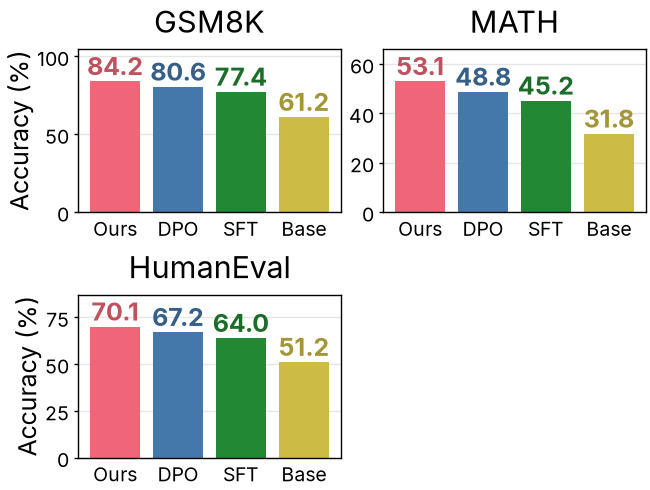

In [2]:
with open("../grouped-bar-chart.json") as f:
    data = json.load(f)
methods = ["Ours", "DPO", "SFT", "Base"]
method_colors = [colors["ours"], colors["series-1"], colors["series-3"], colors["series-4"]]

fig, axes = plt.subplots(2, 2, figsize=(3.25, 3))
x = np.arange(len(methods))
for j, (ax, benchmark) in enumerate(zip(axes.flat, data["benchmarks"])):
    values = [100 * data["scores"][method][j] for method in methods]
    bars = ax.bar(x, values, 0.8, color=method_colors, linewidth=0)
    labels = ax.bar_label(bars, fmt="%.1f", fontweight="bold")
    for label, color in zip(labels, method_colors):
        label.set_color(darken(color))
    ax.set_xticks(x, labels=methods)
    ax.tick_params(axis="x", length=0)
    ax.grid(axis="x", visible=False)
    ax.set_title(benchmark)
axes[0, 0].set_ylabel("Accuracy (%)")
axes[1, 0].set_ylabel("Accuracy (%)")
axes[1, 1].set_axis_off()

fit_height(fig, axes, aspect=0.618)
fig.savefig("grouped-bar-chart.pdf")
fig.savefig("grouped-bar-chart.png", dpi=300)
plt.show()

## stacked-bar-chart

**Figure 2: How each model's answers on MATH split into correct answers and three error types.** Numbers inside segments are percentages of answers; segments under 5% are unlabelled. Most of Ours-7B's errors are reasoning errors (19% of answers), and it makes the fewest format errors of all models, 3% against 4–7%.

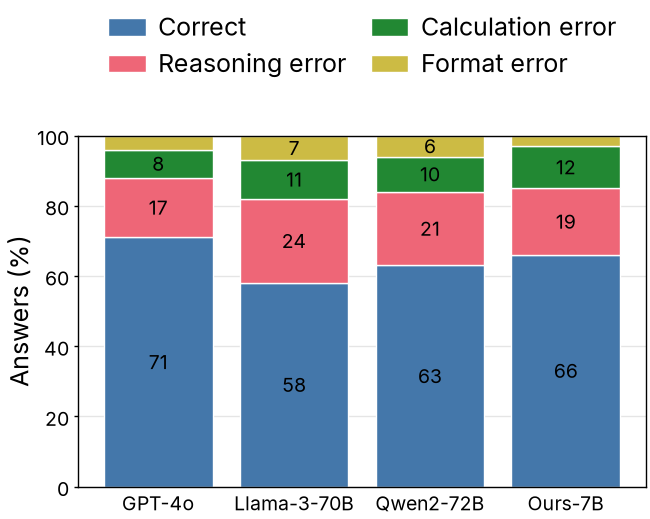

In [3]:
with open("../stacked-bar-chart.json") as f:
    data = json.load(f)
models = data["models"]
category_colors = [colors["series-1"], colors["series-2"], colors["series-3"], colors["series-4"]]

fig, ax = plt.subplots(figsize=(3.25, 2))
x = np.arange(len(models))
below = np.zeros(len(models))
for category, color in zip(data["categories"], category_colors):
    values = 100 * np.array(data["shares"][category])
    bars = ax.bar(x, values, 0.8, bottom=below, color=color, edgecolor="white", linewidth=0.5, label=category)
    ax.bar_label(bars, labels=[f"{v:.0f}" if v >= 5 else "" for v in values], label_type="center", fontsize=7)
    below += values
ax.set_xticks(x, labels=models)
ax.tick_params(axis="x", length=0)
ax.grid(axis="x", visible=False)
ax.set_ylim(0, 100)
ax.set_ylabel("Answers (%)")
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1), borderaxespad=2, ncol=2, frameon=False)

fit_height(fig, ax, aspect=0.618)
fig.savefig("stacked-bar-chart.pdf")
fig.savefig("stacked-bar-chart.png", dpi=300)
plt.show()